**Q1. Data Loading & Understanding**

**a) Load the dataset into Python.**

In [1]:
import pandas as pd

df = pd.read_excel("/content/loan_approval.xlsx")

**b) Display the first 5 rows.**

In [2]:
print(df.head())

              name              city  income  credit_score  loan_amount  \
0     Allison Hill         East Jill  113810           389        39698   
1     Brandon Hall     New Jamesside   44592           729        15446   
2     Rhonda Smith      Lake Roberto   33278           584        11189   
3  Gabrielle Davis  West Melanieview  127196           344        48823   
4     Valerie Gray         Mariastad   66048           496        47174   

   years_employed  points  loan_approved  
0              27      50          False  
1              28      55          False  
2              13      45          False  
3              29      50          False  
4               4      25          False  


**c) Check the shape of the dataset.**

In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (2000, 8)


**d) Display the data types of each column.**

In [4]:
print(df.dtypes)

name              object
city              object
income             int64
credit_score       int64
loan_amount        int64
years_employed     int64
points             int64
loan_approved       bool
dtype: object


**Q2. Data Cleaning**

**a) Check for missing values in the dataset.**

In [5]:
print(df.isnull().sum())

name              0
city              0
income            0
credit_score      0
loan_amount       0
years_employed    0
points            0
loan_approved     0
dtype: int64


**b) Handle missing values appropriately.**

There are different strategies depending on column type:

*  **Numerical columns** **(income, credit_score, loan_amount, years_employed, points):**
    *   Replace with **mean/median** if distribution is normal/skewed.

Example:

In [6]:
df['income'].fillna(df['income'].median(), inplace=True)
df['credit_score'].fillna(df['credit_score'].mean(), inplace=True)


/tmp/ipykernel_487/1874134194.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['income'].fillna(df['income'].median(), inplace=True)
/tmp/ipykernel_487/1874134194.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)'



*   **Categorical columns (name, city):**
    *   Replace with mode (most frequent value).

Example



In [7]:
df['city'].fillna(df['city'].mode()[0], inplace=True)


/tmp/ipykernel_487/2511650230.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['city'].fillna(df['city'].mode()[0], inplace=True)




*   **Target column (loan_approved):**
    *   If missing, drop those rows (since target labels are essential).

Example

In [8]:
df.dropna(subset=['loan_approved'], inplace=True)


**c) Identify Categorical Columns**

In [9]:
categorical_cols = df.select_dtypes(include=['object']).columns
print("Categorical columns:", categorical_cols)


Categorical columns: Index(['name', 'city'], dtype='object')


**Q3. Exploratory Data Analysis (EDA)**

**a) Plot the distribution of the target variable.**




/tmp/ipykernel_487/220734730.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='loan_approved', data=df, palette='Set2')


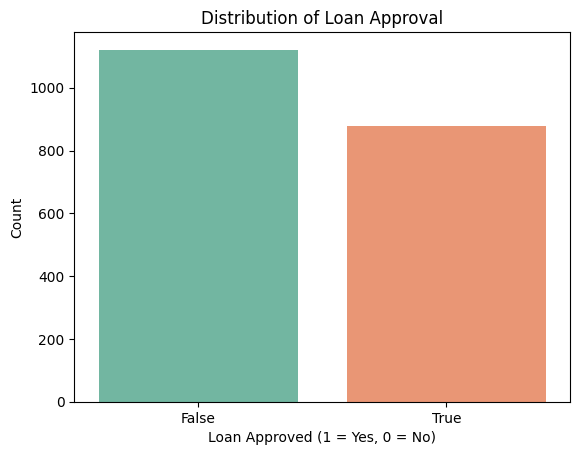

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='loan_approved', data=df, palette='Set2')
plt.title("Distribution of Loan Approval")
plt.xlabel("Loan Approved (1 = Yes, 0 = No)")
plt.ylabel("Count")
plt.show()


**b) Analyze the relationship between one numerical feature and the target variable.**

/tmp/ipykernel_487/3703649029.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loan_approved', y='credit_score', data=df, palette='Set1')


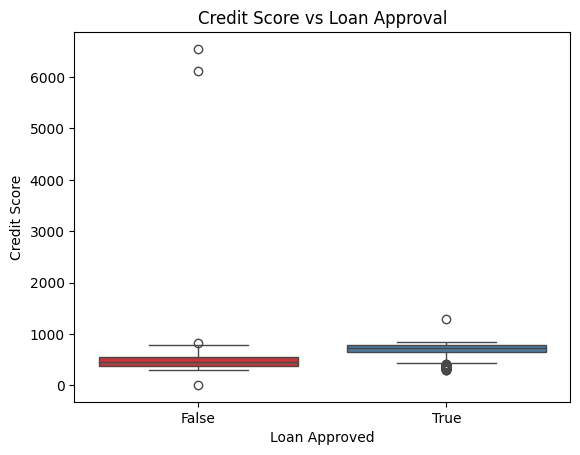

In [11]:
sns.boxplot(x='loan_approved', y='credit_score', data=df, palette='Set1')
plt.title("Credit Score vs Loan Approval")
plt.xlabel("Loan Approved")
plt.ylabel("Credit Score")
plt.show()



**c) Analyze the relationship between Years of Employment and the target variable**

/tmp/ipykernel_487/3289179139.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loan_approved', y='years_employed', data=df, palette='Set3')


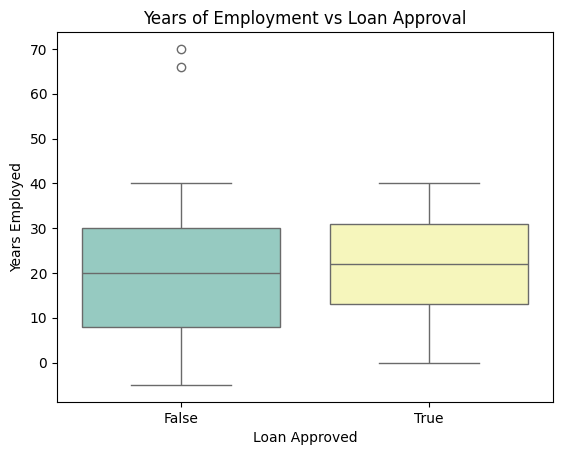

In [12]:
sns.boxplot(x='loan_approved', y='years_employed', data=df, palette='Set3')
plt.title("Years of Employment vs Loan Approval")
plt.xlabel("Loan Approved")
plt.ylabel("Years Employed")
plt.show()


**Q4. Outlier Detection and Treatment**

**a) Detect outliers in numerical columns using the IQR method.**



In [13]:
numeric_cols = ['income','credit_score','loan_amount','years_employed','points']

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col}: {len(outliers)} outliers")


income: 0 outliers
credit_score: 3 outliers
loan_amount: 0 outliers
years_employed: 2 outliers
points: 0 outliers


**b) Treat outliers using capping techniques**

In [15]:
import numpy as np

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower_bound, lower_bound,
                       np.where(df[col] > upper_bound, upper_bound, df[col]))

**Q5. Convert target variables into numerical format suitable for model building and drop unnecessary columns.**

**a) Convert Target Variable**

In [16]:
df['loan_approved'] = df['loan_approved'].astype(int)


**b) Drop Unnecessary Columns**

In [17]:
df.drop(columns=['name'], inplace=True)


**Q6. Feature Selection and Data Splitting**

**a) Separate independent variables (X) and dependent variable (y).**

In [18]:
y = df['loan_approved']

X = df.drop(columns=['loan_approved'])

**b) Split the dataset into training and testing sets**

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)


Training set size: (1600, 6)
Testing set size: (400, 6)


**Q7. Apply feature scaling to the dataset using StandardScaler**

In [21]:
from sklearn.preprocessing import StandardScaler

# Create a copy of the datasets to prevent setting-with-copy warnings
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()

# Fit and transform only on the numerical columns
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Feature scaling applied successfully to numerical columns!")

Feature scaling applied successfully to numerical columns!


**Q8. Logistic Regression Model Building**

**a) Train a Logistic Regression model.**

In [24]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)

log_reg.fit(X_train_scaled[numeric_cols], y_train)

LogisticRegression(max_iter=1000, random_state=42)

**b) Predict the output for test data.**

In [26]:
y_pred = log_reg.predict(X_test_scaled[numeric_cols])

print("Predictions for test data:", y_pred[:10])

Predictions for test data: [0 1 1 1 1 1 0 1 0 1]


**Q9. Model Evaluation – Confusion Matrix**

**a) Generate the confusion matrix.**

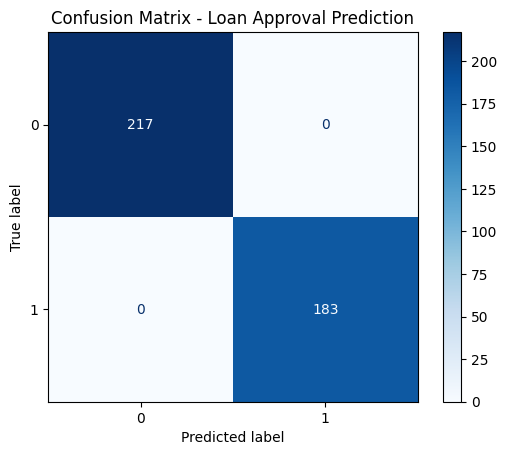

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Loan Approval Prediction")
plt.show()


**b) Interpret the results.**



*   True Negative (TN) → Loans correctly predicted as not approved.

*   False Positive (FP) → Loans incorrectly predicted as approved (model thought they’d be approved but they weren’t).
*   False Negative (FN) → Loans incorrectly predicted as not approved (model missed approvals).


*   True Positive (TP) → Loans correctly predicted as approved.



**Q10. Model Evaluation – ROC Curve & AUC**

**a) Plot the ROC curve.**


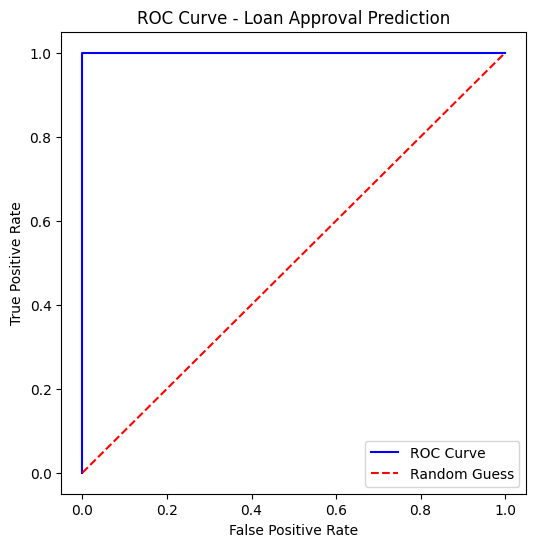

In [29]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Filter X_test_scaled to use only the numeric_cols that were used during fit
y_prob = log_reg.predict_proba(X_test_scaled[numeric_cols])[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color='blue', label='ROC Curve')
plt.plot([0,1], [0,1], color='red', linestyle='--', label='Random Guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Loan Approval Prediction")
plt.legend()
plt.show()

**b) Calculate the AUC score.**